In [ ]:
# Step 4: Exploratory Data Analysis (EDA)

## Objectives

# 1. Understand the structure of cleaned datasets.
# 2. Analyse customer churn distribution.
# 3. Study numerical variables.
# 4. Study categorical variables.
# 5. Identify important churn patterns.
# 6. Compare customer behaviour within each dataset.
# 7. Generate visualizations.
# 8. Save charts and EDA reports.

# Note:
# Telecom and banking datasets will be analysed separately.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import json
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("EDA libraries imported successfully.")

EDA libraries imported successfully.


In [2]:
# Define project paths

from pathlib import Path

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

CHARTS = PROJECT_ROOT / "outputs" / "charts"
REPORTS = PROJECT_ROOT / "outputs" / "evaluation_reports"

CHARTS.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data:", DATA_PROCESSED)
print("Charts folder:", CHARTS)

Project root: d:\Dynamic_AI_Chatbot_Project
Processed data: d:\Dynamic_AI_Chatbot_Project\data\processed
Charts folder: d:\Dynamic_AI_Chatbot_Project\outputs\charts


In [3]:
# Load cleaned datasets

telecom_excel = pd.read_excel(
    DATA_PROCESSED / "telecom_churn_cleaned.xlsx",
    engine="openpyxl"
)

banking_data = pd.read_csv(
    DATA_PROCESSED / "banking_churn_cleaned.csv"
)

telecom_csv = pd.read_csv(
    DATA_PROCESSED / "telecom_churn_second_cleaned.csv"
)

print("Cleaned datasets loaded successfully.")

print("\nMain Telecom:", telecom_excel.shape)
print("Banking:", banking_data.shape)
print("Second Telecom:", telecom_csv.shape)

Cleaned datasets loaded successfully.

Main Telecom: (7043, 33)
Banking: (10000, 17)
Second Telecom: (7043, 21)


In [4]:
# Inspect dataset information

datasets = {
    "Main Telecom": telecom_excel,
    "Banking": banking_data,
    "Second Telecom": telecom_csv
}

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("\nDataset shape:", df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nStatistical summary:")
    display(df.describe(include="all").T)


Main Telecom

Dataset shape: (7043, 33)

Column names:
['customerid', 'count', 'country', 'state', 'city', 'zip_code', 'lat_long', 'latitude', 'longitude', 'gender', 'senior_citizen', 'partner', 'dependents', 'tenure_months', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges', 'churn_label', 'churn_value', 'churn_score', 'cltv', 'churn_reason']

Data types:
customerid               str
count                  int64
country                  str
state                    str
city                     str
zip_code               int64
lat_long                 str
latitude             float64
longitude            float64
gender                   str
senior_citizen           str
partner                  str
dependents               str
tenure_months          int64
phone_service            str
multi

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerid,7043,7043,3668-QPYBK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
count,7043.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
country,7043,1,United States,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,7043,1,California,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,7043,1129,Los Angeles,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zip_code,7043.0,NaN,NaN,NaN,93521.964646,1865.794555,90001.0,92102.0,93552.0,95351.0,96161.0
lat_long,7043,1652,"33.964131, -118.272783",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,7043.0,NaN,NaN,NaN,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
longitude,7043.0,NaN,NaN,NaN,-119.79888,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Banking

Dataset shape: (10000, 17)

Column names:
['customerid', 'surname', 'creditscore', 'location', 'gender', 'age', 'tenure', 'account_balance', 'numofproducts', 'hascrcard', 'isactivemember', 'estimatedsalary', 'exited', 'complain', 'satisfaction_score', 'card_type', 'point_earned']

Data types:
customerid              int64
surname                   str
creditscore             int64
location                  str
gender                    str
age                     int64
tenure                  int64
account_balance       float64
numofproducts           int64
hascrcard               int64
isactivemember          int64
estimatedsalary       float64
exited                  int64
complain                int64
satisfaction_score      int64
card_type                 str
point_earned            int64
dtype: object

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerid,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
creditscore,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
location,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
account_balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
numofproducts,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0
hascrcard,10000.0,NaN,NaN,NaN,0.7055,0.45584,0.0,0.0,1.0,1.0,1.0



Second Telecom

Dataset shape: (7043, 21)

Column names:
['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents', 'tenure', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod', 'monthlycharges', 'totalcharges', 'churn']

Data types:
customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges        float64
churn                   str
dtype: object

St

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerid,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seniorcitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
phoneservice,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
multiplelines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
internetservice,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
onlinesecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Identify churn target columns

target_candidates = [
    "churn",
    "exited",
    "churn_value",
    "churn_label",
    "attrition",
    "attrition_flag"
]

def find_target_column(df):

    normalized_columns = {
        re.sub(r"[^a-z0-9]", "", str(col).lower()): col
        for col in df.columns
    }

    for candidate in target_candidates:

        normalized = re.sub(
            r"[^a-z0-9]",
            "",
            candidate.lower()
        )

        if normalized in normalized_columns:
            return normalized_columns[normalized]

    return None


for name, df in datasets.items():

    target = find_target_column(df)

    print("\nDataset:", name)
    print("Target column:", target)

    if target:
        print("\nChurn distribution:")
        display(
            df[target].value_counts(dropna=False).to_frame("Count")
        )


Dataset: Main Telecom
Target column: churn_value

Churn distribution:


,Count
churn_value,
0,5174
1,1869



Dataset: Banking
Target column: exited

Churn distribution:


,Count
exited,
0,7962
1,2038



Dataset: Second Telecom
Target column: churn

Churn distribution:


,Count
churn,
No,5174
Yes,1869


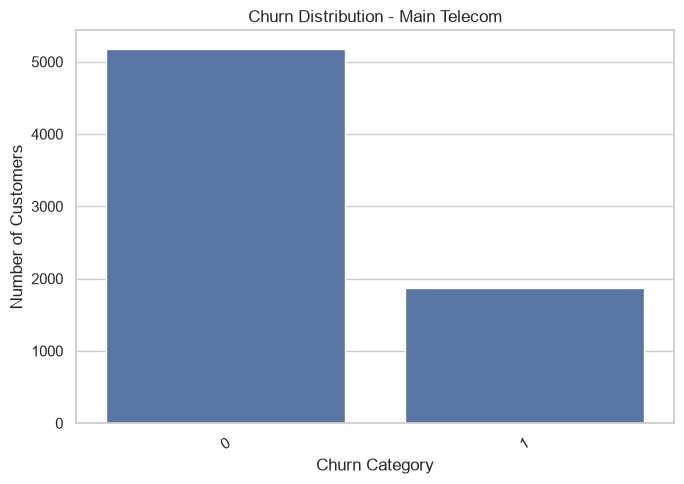

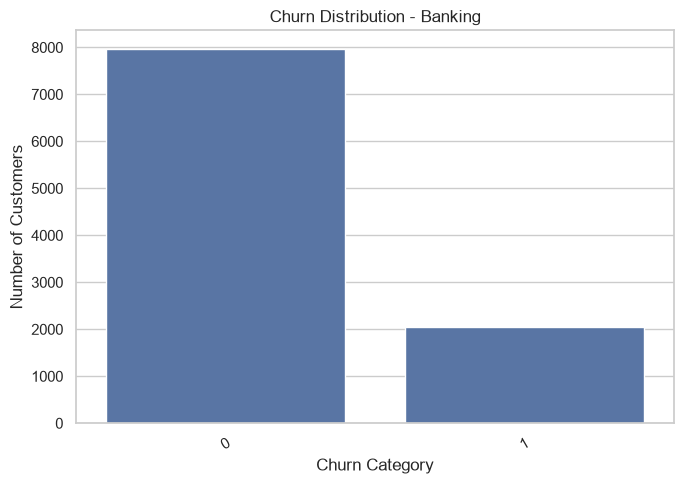

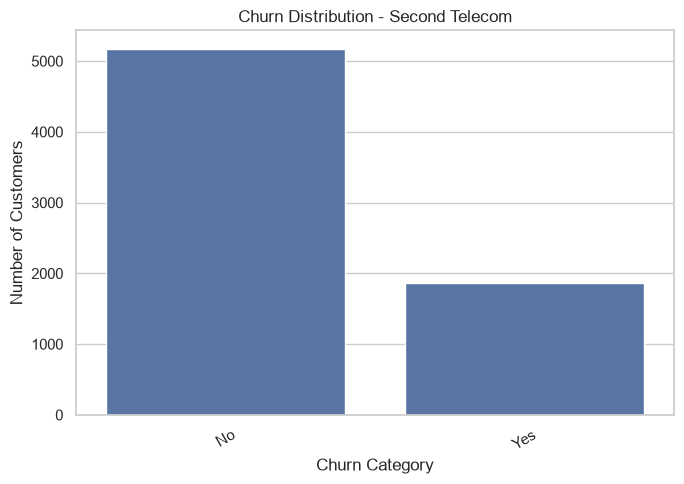

In [6]:
# Visualize churn distribution

for name, df in datasets.items():

    target = find_target_column(df)

    if target is None:
        print("Target column not identified for:", name)
        continue

    plt.figure(figsize=(7, 5))

    sns.countplot(
        data=df,
        x=target
    )

    plt.title(f"Churn Distribution - {name}")
    plt.xlabel("Churn Category")
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=30)

    plt.tight_layout()

    filename = re.sub(
        r"[^a-z0-9]+",
        "_",
        name.lower()
    )

    plt.savefig(
        CHARTS / f"{filename}_churn_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


Dataset: Main Telecom
Numerical columns: ['count', 'zip_code', 'latitude', 'longitude', 'tenure_months', 'monthly_charges', 'total_charges', 'churn_value', 'churn_score', 'cltv']


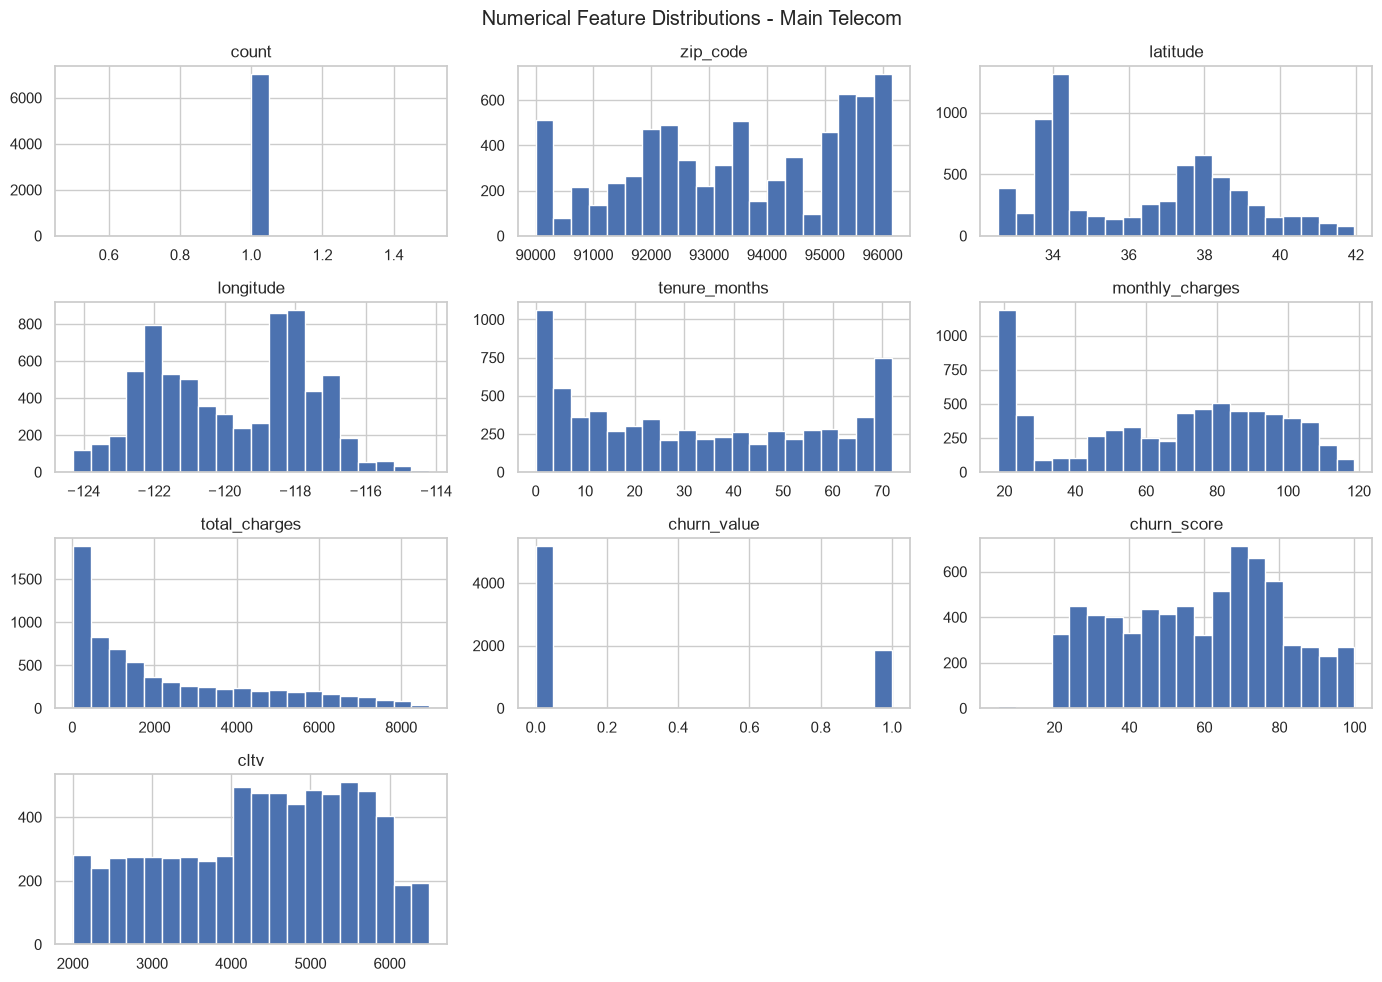


Dataset: Banking
Numerical columns: ['customerid', 'creditscore', 'age', 'tenure', 'account_balance', 'numofproducts', 'hascrcard', 'isactivemember', 'estimatedsalary', 'exited', 'complain', 'satisfaction_score', 'point_earned']


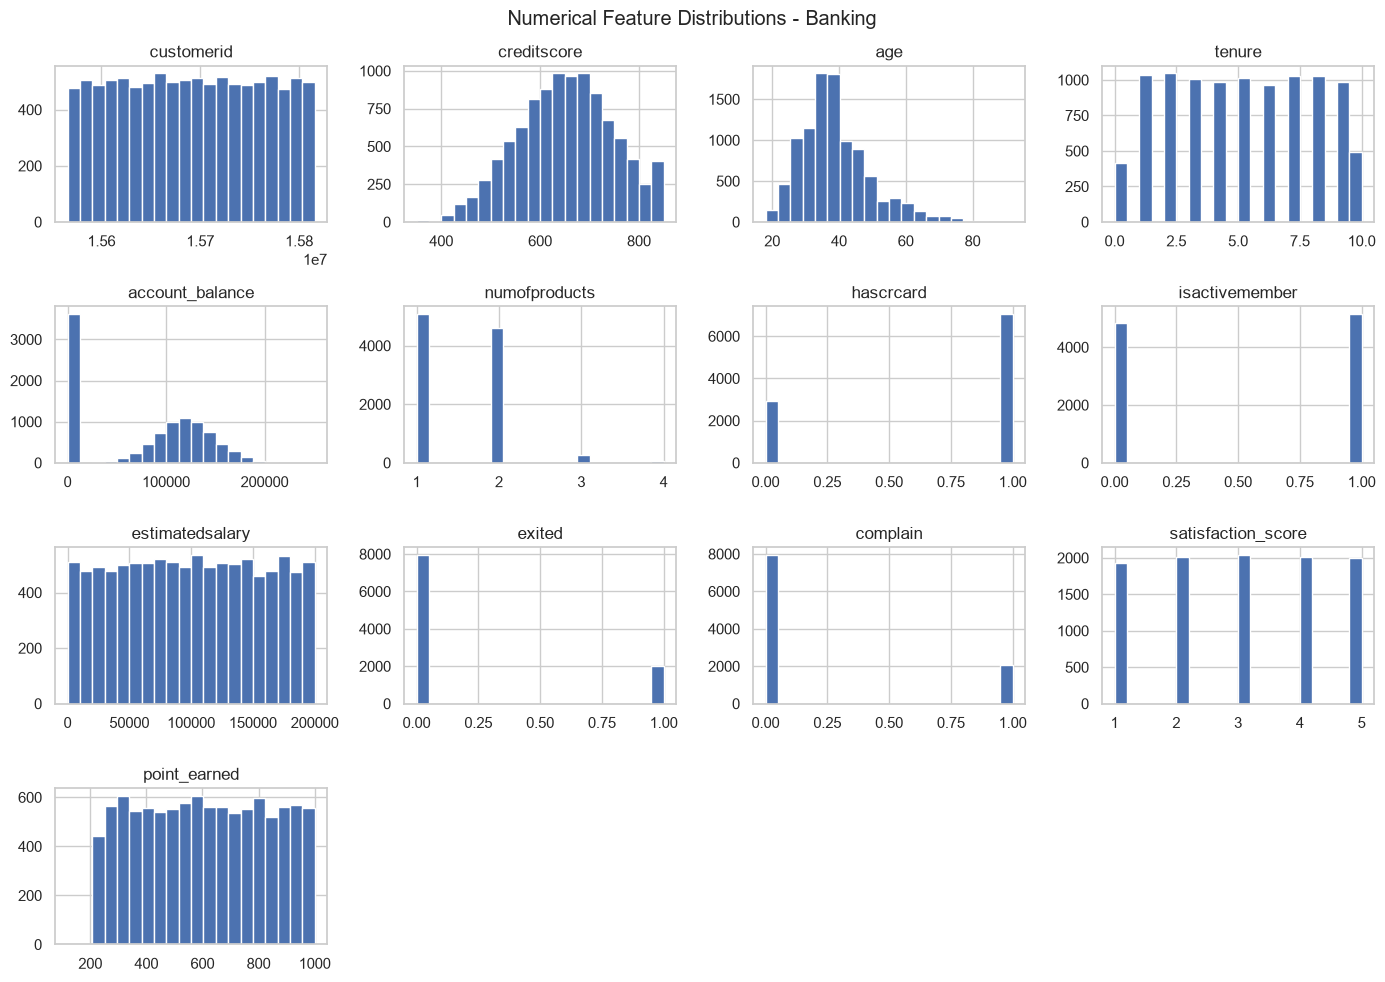


Dataset: Second Telecom
Numerical columns: ['seniorcitizen', 'tenure', 'monthlycharges', 'totalcharges']


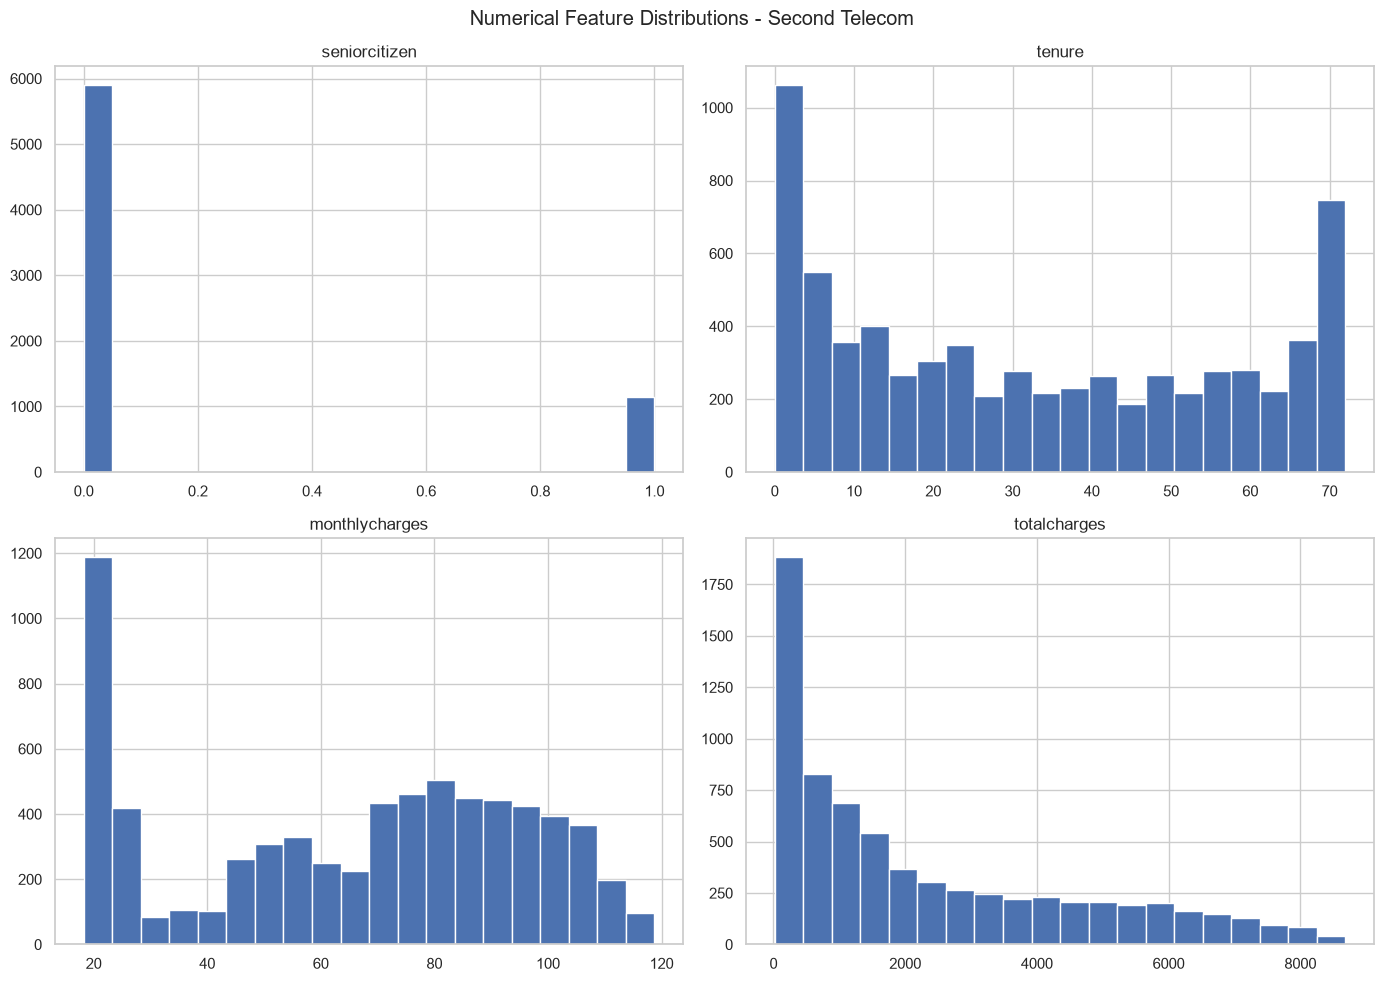

In [7]:
# Analyse numerical columns

for name, df in datasets.items():

    numerical_columns = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    print("\nDataset:", name)
    print("Numerical columns:", numerical_columns)

    if len(numerical_columns) == 0:
        continue

    df[numerical_columns].hist(
        figsize=(14, 10),
        bins=20
    )

    plt.suptitle(
        f"Numerical Feature Distributions - {name}"
    )

    plt.tight_layout()

    filename = re.sub(
        r"[^a-z0-9]+",
        "_",
        name.lower()
    )

    plt.savefig(
        CHARTS / f"{filename}_numerical_distributions.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

In [8]:
# Analyse categorical columns

for name, df in datasets.items():

    categorical_columns = df.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    print("\nDataset:", name)

    print("Categorical columns:", categorical_columns)

    for column in categorical_columns[:6]:

        print("\nColumn:", column)

        print(
            df[column].value_counts(dropna=False).head(10)
        )


Dataset: Main Telecom
Categorical columns: ['customerid', 'country', 'state', 'city', 'lat_long', 'gender', 'senior_citizen', 'partner', 'dependents', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method', 'churn_label', 'churn_reason']

Column: customerid
customerid
3668-QPYBK    1
9237-HQITU    1
9305-CDSKC    1
7892-POOKP    1
0280-XJGEX    1
4190-MFLUW    1
8779-QRDMV    1
1066-JKSGK    1
6467-CHFZW    1
8665-UTDHZ    1
Name: count, dtype: int64

Column: country
country
United States    7043
Name: count, dtype: int64

Column: state
state
California    7043
Name: count, dtype: int64

Column: city
city
Los Angeles      305
San Diego        150
San Jose         112
Sacramento       108
San Francisco    104
Fresno            64
Long Beach        60
Oakland           52
Stockton          44
Glendale          40
Name: count, dtyp

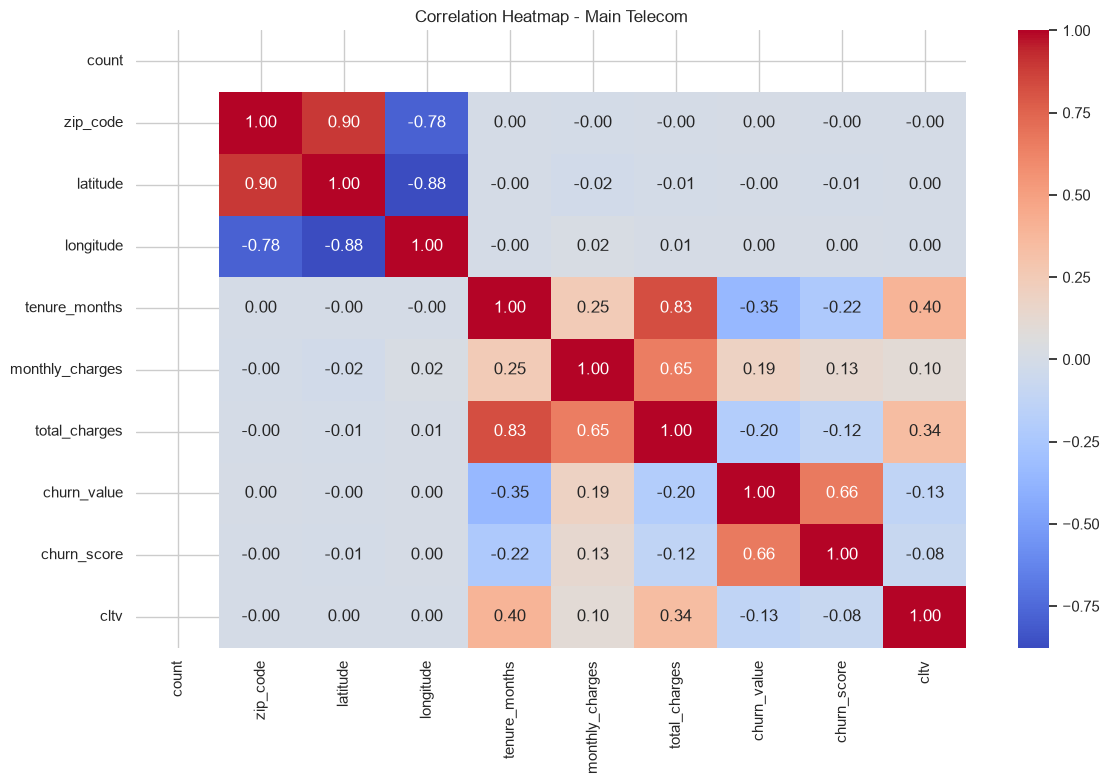

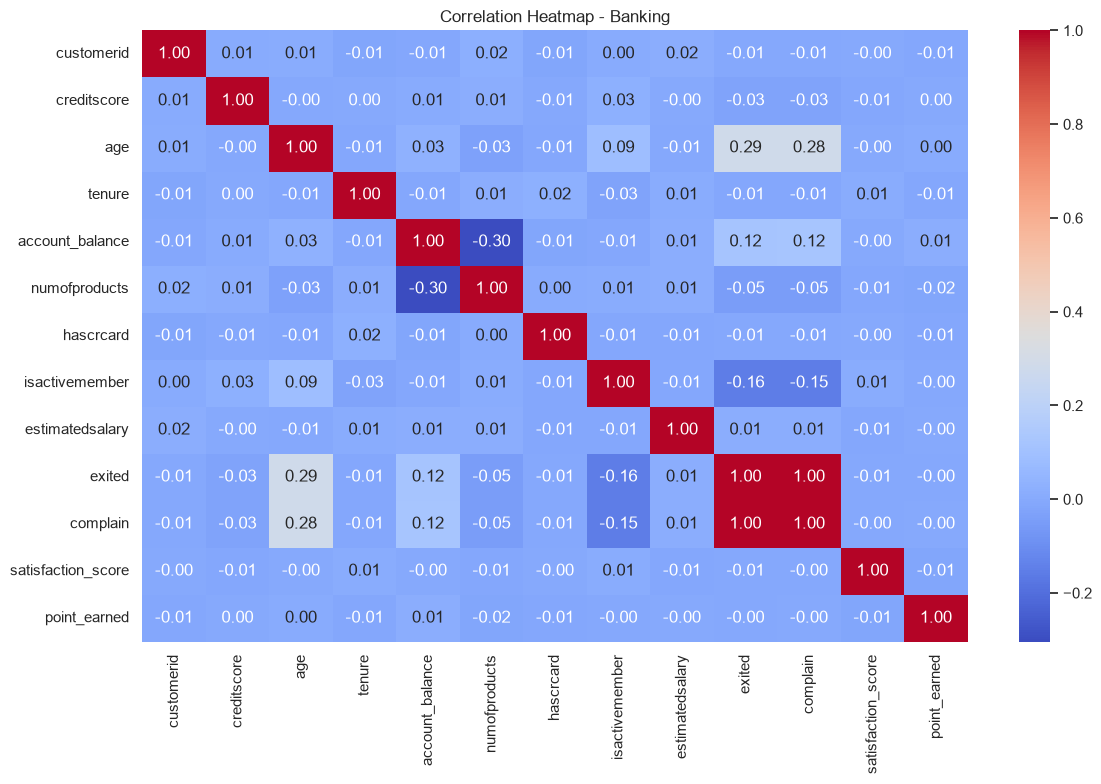

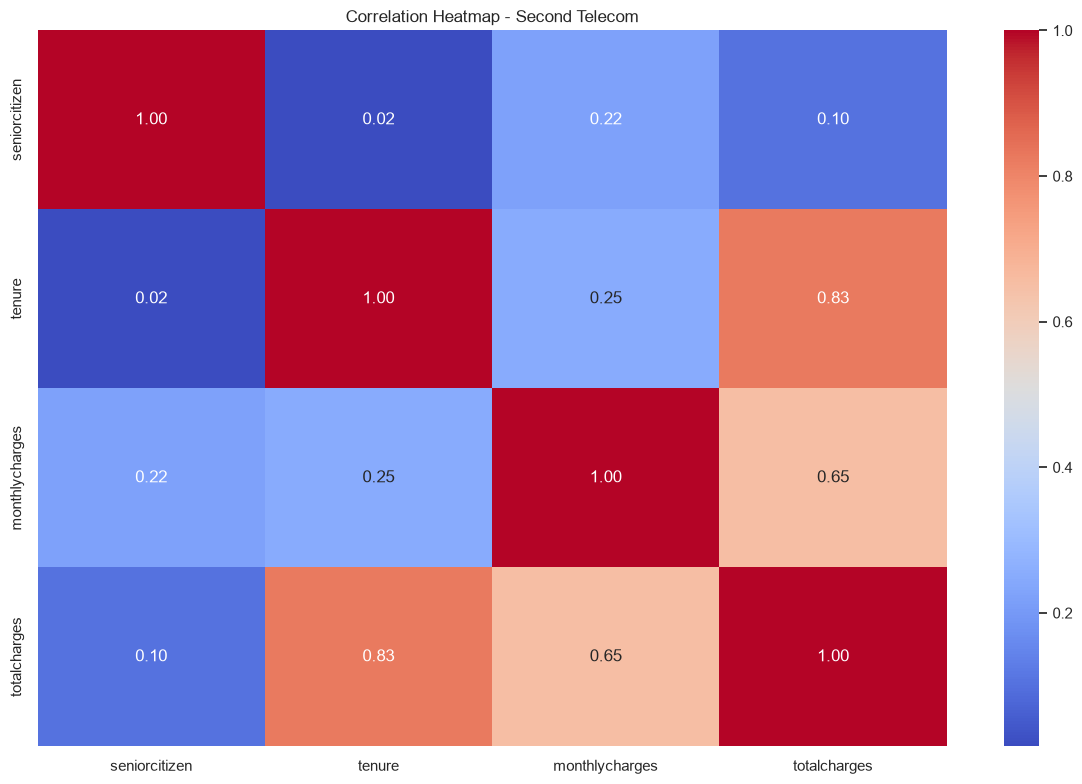

In [9]:
# Correlation analysis

for name, df in datasets.items():

    numerical_df = df.select_dtypes(
        include=np.number
    )

    if numerical_df.shape[1] < 2:
        print("Not enough numerical columns:", name)
        continue

    plt.figure(figsize=(12, 8))

    correlation = numerical_df.corr()

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title(f"Correlation Heatmap - {name}")

    plt.tight_layout()

    filename = re.sub(
        r"[^a-z0-9]+",
        "_",
        name.lower()
    )

    plt.savefig(
        CHARTS / f"{filename}_correlation_heatmap.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

In [10]:
# Analyse churn by categorical features

for name, df in datasets.items():

    target = find_target_column(df)

    if target is None:
        print("Target not found:", name)
        continue

    categorical_columns = df.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    categorical_columns = [
        col for col in categorical_columns
        if col != target
    ]

    for column in categorical_columns[:5]:

        summary = pd.crosstab(
            df[column],
            df[target],
            normalize="index"
        ) * 100

        print("\nDataset:", name)
        print("Feature:", column)
        print("Churn distribution by category (%):")

        display(summary.round(2))


Dataset: Main Telecom
Feature: customerid
Churn distribution by category (%):


churn_value,0,1
customerid,,
0002-ORFBO,100.0,0.0
0003-MKNFE,100.0,0.0
0004-TLHLJ,0.0,100.0
0011-IGKFF,0.0,100.0
0013-EXCHZ,0.0,100.0
...,...,...
9987-LUTYD,100.0,0.0
9992-RRAMN,0.0,100.0
9992-UJOEL,100.0,0.0



Dataset: Main Telecom
Feature: country
Churn distribution by category (%):


churn_value,0,1
country,,
United States,73.46,26.54



Dataset: Main Telecom
Feature: state
Churn distribution by category (%):


churn_value,0,1
state,,
California,73.46,26.54


... (18 outputs left out)


Dataset: Second Telecom
Feature: dependents
Churn distribution by category (%):


churn,No,Yes
dependents,,
No,68.72,31.28
Yes,84.55,15.45



Dataset: Second Telecom
Feature: phoneservice
Churn distribution by category (%):


churn,No,Yes
phoneservice,,
No,75.07,24.93
Yes,73.29,26.71


In [11]:
# Generate EDA summary report

eda_report = {}

for name, df in datasets.items():

    target = find_target_column(df)

    eda_report[name] = {
        "rows": int(df.shape[0]),
        "columns": int(df.shape[1]),
        "numerical_columns": df.select_dtypes(
            include=np.number
        ).columns.tolist(),
        "categorical_columns": df.select_dtypes(
            include=["object", "category", "string"]
        ).columns.tolist(),
        "target_column": target,
        "missing_values": {
            str(col): int(count)
            for col, count in df.isnull().sum().items()
        }
    }

    if target is not None:

        eda_report[name]["target_distribution"] = {
            str(key): int(value)
            for key, value in df[target].value_counts(
                dropna=False
            ).items()
        }


report_path = REPORTS / "eda_summary_report.json"

with open(report_path, "w", encoding="utf-8") as file:

    json.dump(
        eda_report,
        file,
        indent=4,
        default=str
    )

print("EDA report saved:", report_path)

EDA report saved: d:\Dynamic_AI_Chatbot_Project\outputs\evaluation_reports\eda_summary_report.json


In [12]:
# Verify saved charts and reports

print("EDA OUTPUT VERIFICATION")
print("-" * 50)

print("\nCharts:")

for file in CHARTS.iterdir():
    if file.is_file():
        print(file.name)

print("\nReports:")

for file in REPORTS.iterdir():
    if file.is_file():
        print(file.name)

print("\nEDA stage completed.")

EDA OUTPUT VERIFICATION
--------------------------------------------------

Charts:
banking_churn_distribution.png
banking_correlation_heatmap.png
banking_numerical_distributions.png
main_telecom_churn_distribution.png
main_telecom_correlation_heatmap.png
main_telecom_numerical_distributions.png
second_telecom_churn_distribution.png
second_telecom_correlation_heatmap.png
second_telecom_numerical_distributions.png

Reports:
eda_summary_report.json

EDA stage completed.
